In [1]:
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Import variables from config.py
from heart.config import (
    DATA_RAW, FIGURES, SEED, TARGET, NUM_COLS, BINARY_COLS, NOMINAL_COLS,
)

# Set global options for pandas and seaborn
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 100

# Define a function to save figures
def save_fig(name: str) -> None:
    """Save the current figure into reports/figures/."""
    FIGURES.mkdir(parents=True, exist_ok=True)
    plt.savefig(FIGURES / f"{name}.png", dpi=150, bbox_inches="tight")

# Heart Disease Prediction: Exploratory Data Analysis

**Objective:** Understand the dataset well enough to decide how to clean it, which
features matter, and what risks to model on. This notebook makes no model comparisons,
those are in `02_modeling.ipynb`.

**Problem framing:** Binary classification of heart disease presence from clinical
measurements. This is a screening-style task, so a missed case (false negative) is
costlier than a false alarm (false positive). Recall will matter alongside accuracy.

**Dataset Source.** <Heart Failure Prediction Dataset, (https://www.kaggle.com/datasets/fedesoriano/heart-failure-prediction)>.

## Attribute Information
| # | Name | Description | Values |
|---|---|---|---|
| 1 | Age | Age of the patient | years |
| 2 | Sex | Sex of the patient | M: Male, F: Female |
| 3 | ChestPainType | Chest pain type | TA: Typical Angina, ATA: Atypical Angina, NAP: Non-Anginal Pain, ASY: Asymptomatic |
| 4 | RestingBP | Resting blood pressure | mm Hg |
| 5 | Cholesterol| Serum cholesterol | mm/dl |
| 6 | FastingBS | Fasting blood sugar | 1: if FastingBS > 120 mg/dl, 0: otherwise |
| 7 | RestingECG | Resting electrocardiogram results | Normal: Normal, ST: having ST-T wave abnormality (T wave inversions and/or ST elevation or depression of > 0.05 mV), LVH: showing probable or definite left ventricular hypertrophy by Estes' criteria|
| 8 | MaxHR | Maximum heart rate achieved | Numeric value between 60 and 202 |
| 9 | ExerciseAngina | Exercise-induced angina | Y: Yes, N: No |
| 10 | Oldpeak | Oldpeak = ST | Numeric value measured in depression |
| 11 | ST_Slope | The slope of the peak exercise ST segment | Up: upsloping, Flat: flat, Down: downsloping |
| 12 | HeartDisease | Output class | 1: heart disease, 0: Normal |

## Source Information
This dataset was created by combining different datasets already available independently but not combined before. In this dataset, 5 heart datasets are combined over 11 common features which makes it the largest heart disease dataset available so far for research purposes. The five datasets used for its curation are:

    Cleveland: 303 observations
    Hungarian: 294 observations
    Switzerland: 123 observations
    Long Beach VA: 200 observations
    Stalog (Heart) Data Set: 270 observations

Total: 1190 observations Duplicated: 272 observations

Final dataset: 918 observations

In [2]:
# Load the raw data and display basic information
df = pd.read_csv(DATA_RAW)

print("shape:", df.shape)
print("missing cells:", int(df.isna().sum().sum()))
print("duplicate rows:", int(df.duplicated().sum()))
print()
print(df[TARGET].value_counts().rename("count").to_frame()
      .assign(share=lambda d: (d["count"] / len(df)).round(3)))
df.dtypes

shape: (918, 12)
missing cells: 0
duplicate rows: 0

              count  share
HeartDisease              
1               508  0.553
0               410  0.447


Age                 int64
Sex                   str
ChestPainType         str
RestingBP           int64
Cholesterol         int64
FastingBS           int64
RestingECG            str
MaxHR               int64
ExerciseAngina        str
Oldpeak           float64
ST_Slope              str
HeartDisease        int64
dtype: object

In [3]:
# Check if the categorical columns have the expected levels
expected_levels = {
    "Sex": {"M", "F"},
    "ChestPainType": {"TA", "ATA", "NAP", "ASY"},
    "RestingECG": {"Normal", "ST", "LVH"},
    "ExerciseAngina": {"Y", "N"},
    "ST_Slope": {"Up", "Flat", "Down"},
    "FastingBS": {0, 1},
    TARGET: {0, 1},
}
for col, levels in expected_levels.items():
    found = set(df[col].unique())
    status = "OK" if found == levels else f"MISMATCH -> {found ^ levels}"
    print(f"{col:15s} {status}")

Sex             OK
ChestPainType   OK
RestingECG      OK
ExerciseAngina  OK
ST_Slope        OK
FastingBS       OK
HeartDisease    OK


# Findings

This dataset has 918 rows and 11 features + 1 target columns, no missing or duplicate rows. It is roughly balanced on the target variable since the split is 508 with disease and 410 without.
This means accuracy can be a valid metric alongside recall since this is a medical dataset and a FN is much more costly than a FP. Categories match the data information from Kaggle.

In [4]:
# Display descriptive statistics for all columns
df.describe(include="all")

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
count,918.000000,918,918,918.000000,918.000000,918.000000,918,918.000000,918,918.000000,918,918.000000
unique,NaN,2,4,NaN,NaN,NaN,3,NaN,2,NaN,3,NaN
top,NaN,M,ASY,NaN,NaN,NaN,Normal,NaN,N,NaN,Flat,NaN
freq,NaN,725,496,NaN,NaN,NaN,552,NaN,547,NaN,460,NaN
mean,53.510893,NaN,NaN,132.396514,198.799564,0.233115,NaN,136.809368,NaN,0.887364,NaN,0.553377
std,9.432617,NaN,NaN,18.514154,109.384145,0.423046,NaN,25.460334,NaN,1.066570,NaN,0.497414
min,28.000000,NaN,NaN,0.000000,0.000000,0.000000,NaN,60.000000,NaN,-2.600000,NaN,0.000000
25%,47.000000,NaN,NaN,120.000000,173.250000,0.000000,NaN,120.000000,NaN,0.000000,NaN,0.000000
50%,54.000000,NaN,NaN,130.000000,223.000000,0.000000,NaN,138.000000,NaN,0.600000,NaN,1.000000
75%,60.000000,NaN,NaN,140.000000,267.000000,0.000000,NaN,156.000000,NaN,1.500000,NaN,1.000000


In [5]:
# Check for zero values in RestingBP and Cholesterol, and negative values in Oldpeak, impossible values for these features
zero_counts = (df[["RestingBP", "Cholesterol"]] == 0).sum()
print(zero_counts)
print()
print("Oldpeak < 0:", int((df["Oldpeak"] < 0).sum()), "rows")
print(df.loc[df["Oldpeak"] < 0, ["Age", "Sex", "Oldpeak", "ST_Slope", TARGET]].head(10))

RestingBP        1
Cholesterol    172
dtype: int64

Oldpeak < 0: 13 rows
     Age Sex  Oldpeak ST_Slope  HeartDisease
321   63   M     -0.9     Flat             1
324   46   M     -2.6     Flat             1
325   42   M     -1.5     Down             1
326   45   M     -0.1       Up             0
331   56   M     -1.0       Up             1
332   38   M     -1.1       Up             0
334   51   M     -0.7       Up             1
335   62   M     -0.8     Flat             1
352   56   M     -1.0     Down             1
407   62   M     -0.5     Flat             1


In [6]:
chol_zero = df["Cholesterol"].eq(0).rename("chol_zero")

# Disease rate with and without a recorded cholesterol
print(df.groupby(chol_zero)[TARGET].agg(rate="mean", n="count").round(3))

# Is the difference bigger than chance?
chi2, p, _, _ = stats.chi2_contingency(pd.crosstab(chol_zero, df[TARGET]))
print(f"\nchi-square p-value: {p:.2e}")

# Who has the zeros?
print("\nSex mix (share of rows):")
print(pd.crosstab(chol_zero, df["Sex"], normalize="index").round(3))
print("\nChest pain type (share of rows):")
print(pd.crosstab(chol_zero, df["ChestPainType"], normalize="index").round(3))
print("\nMean age:")
print(df.groupby(chol_zero)["Age"].mean().round(1))

            rate    n
chol_zero            
False      0.477  746
True       0.884  172

chi-square p-value: 9.50e-22

Sex mix (share of rows):
Sex            F      M
chol_zero              
False      0.244  0.756
True       0.064  0.936

Chest pain type (share of rows):
ChestPainType    ASY    ATA    NAP     TA
chol_zero                                
False          0.496  0.223  0.227  0.055
True           0.733  0.041  0.198  0.029

Mean age:
chol_zero
False    52.9
True     56.2
Name: Age, dtype: float64


# Findings

There are 172 zeros in Cholesterol and 1 zero in RestingBP, both physiologically impossible values. There are also 13 rows with Oldpeak < 0 which are worth investigating.

We see that the rate of having the disease is much higher (0.88) for these zero cholesterol rows which, along with a very small chi-square p-value compared to the chance limit of 0.05 that shows it is not based on luck, means this carries statistical importance. Further analysis points that a lot of the zero cholesterol rows were Male, with ASY chest pain type and had the disease.

The restingBP is just one row which can be imputed without affecting the dataset.

Negative Oldpeak is unusual but not impossible, these rows can be kept at default since they are not wrong measurements.

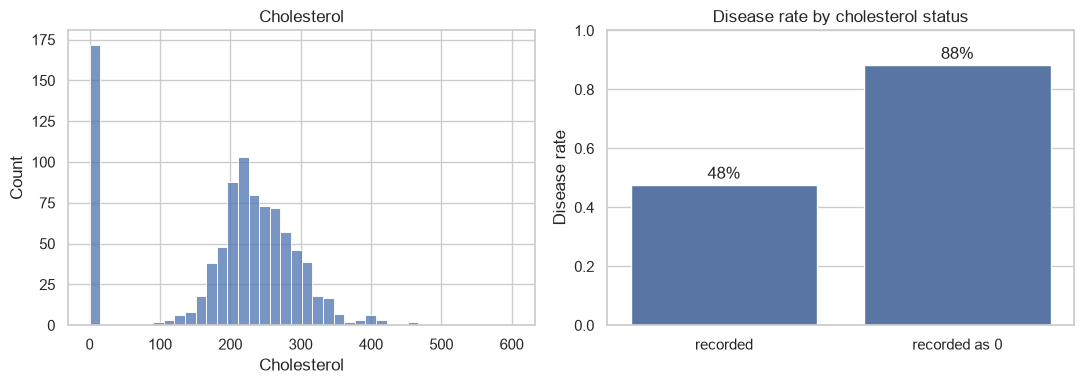

In [7]:
# Visualize the distribution of cholesterol and the disease rate by cholesterol status to support the above findings
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

sns.histplot(df["Cholesterol"], bins=40, ax=axes[0])
axes[0].set_title("Cholesterol")

rate = df.groupby(chol_zero)[TARGET].mean()
sns.barplot(x=["recorded", "recorded as 0"], y=rate.values, ax=axes[1])
axes[1].set_ylim(0, 1)
axes[1].set_ylabel("Disease rate")
axes[1].set_title("Disease rate by cholesterol status")
for i, v in enumerate(rate.values):
    axes[1].text(i, v + 0.02, f"{v:.0%}", ha="center")

plt.tight_layout()
save_fig("01_cholesterol_zeros")
plt.show()

In [8]:
# Disease rate by chest pain type and cholesterol status
(df.groupby(["ChestPainType", chol_zero])[TARGET]
   .agg(rate="mean", n="count").round(3).unstack())

rate            n      
chol_zero      False  True  False True 
ChestPainType                          
ASY            0.741  0.937   370   126
ATA            0.127  0.429   166     7
NAP            0.272  0.765   169    34
TA             0.366  1.000    41     5

In [9]:
# Check if the zeros are clustered in the dataset
zero_idx = df.index[df["Cholesterol"].eq(0)]
print("first/last row:", zero_idx.min(), zero_idx.max(), "count:", len(zero_idx))
print(zero_idx.to_series().diff().value_counts().head())

first/last row: 293 536 count: 172
1.0    150
2.0     10
3.0      4
6.0      2
4.0      2
Name: count, dtype: int64


# Findings

The zeros in cholesterol seem to be clustered between rows 293-536. Also, the patients with 0 cholesterol seem to be sicker for every category of ChestPainType (Only ASY and NAP have statistical importance) which shows that this features does not affect the zero rows differently than the others.

This could mean that these measurements came from the same hospital that perhaps did not measure cholesterol.
Since this dataset is a combination of many datasets, this can be true but it cannot be validated for sure. To avoid creating a model that leans too heavily on the missing indicator, it should be trained both with the missing indicator and without it or even without the whole Cholesterol feature to compare results and observe the impact.

In [10]:
# Create a cleaned version of the dataset by replacing zeros in RestingBP and Cholesterol with NaN for EDA purposes
df_clean = df.copy()
df_clean[["RestingBP", "Cholesterol"]] = df_clean[["RestingBP", "Cholesterol"]].replace(0, np.nan)

In [11]:
# Count outliers using IQR method
def iqr_outliers(s: pd.Series) -> int:
    s = s.dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())

# Display summary statistics for numeric columns in the cleaned dataset
num = df_clean[NUM_COLS]
summary = pd.DataFrame({
    "missing": num.isna().sum(),
    "mean": num.mean(),
    "median": num.median(),
    "std": num.std(),
    "skew": num.skew(),
    "iqr_outliers": num.apply(iqr_outliers),
}).round(2)
summary



,missing,mean,median,std,skew,iqr_outliers
Age,0,53.51,54.0,9.43,-0.20,0
RestingBP,1,132.54,130.0,18.00,0.61,27
Cholesterol,172,244.64,237.0,59.15,1.24,23
MaxHR,0,136.81,138.0,25.46,-0.14,2
Oldpeak,0,0.89,0.6,1.07,1.02,16


In [12]:
# Print the outliers to determine if they are valid or erroneous values
for col in NUM_COLS:
    outliers = df_clean[col][(df_clean[col] < df_clean[col].quantile(0.25) - 1.5 * (df_clean[col].quantile(0.75) - df_clean[col].quantile(0.25))) |
                              (df_clean[col] > df_clean[col].quantile(0.75) + 1.5 * (df_clean[col].quantile(0.75) - df_clean[col].quantile(0.25)))]
    print(f"\nOutliers in {col}:")
    print(outliers)


Outliers in Age:
Series([], Name: Age, dtype: int64)

Outliers in RestingBP:
109    190.0
123    180.0
189    180.0
190    180.0
241    200.0
274    180.0
275    180.0
278    180.0
314     80.0
365    200.0
372    185.0
399    200.0
411    180.0
423    180.0
475    178.0
550    172.0
585    180.0
592    190.0
673    174.0
702    178.0
725    180.0
732    200.0
759    192.0
774    178.0
780    180.0
855    180.0
880    172.0
Name: RestingBP, dtype: float64

Outliers in Cholesterol:
28     468.0
30     518.0
69     412.0
76     529.0
78     100.0
98      85.0
102    392.0
103    466.0
123    393.0
132    388.0
149    603.0
182    404.0
250    491.0
256    394.0
444    100.0
496    458.0
498    384.0
613    385.0
616    564.0
624    407.0
667    417.0
796    409.0
803    394.0
Name: Cholesterol, dtype: float64

Outliers in MaxHR:
370    63
390    60
Name: MaxHR, dtype: int64

Outliers in Oldpeak:
68     4.0
166    5.0
324   -2.6
500    4.0
521    4.0
537    4.0
559    4.0
624    4.0
702 

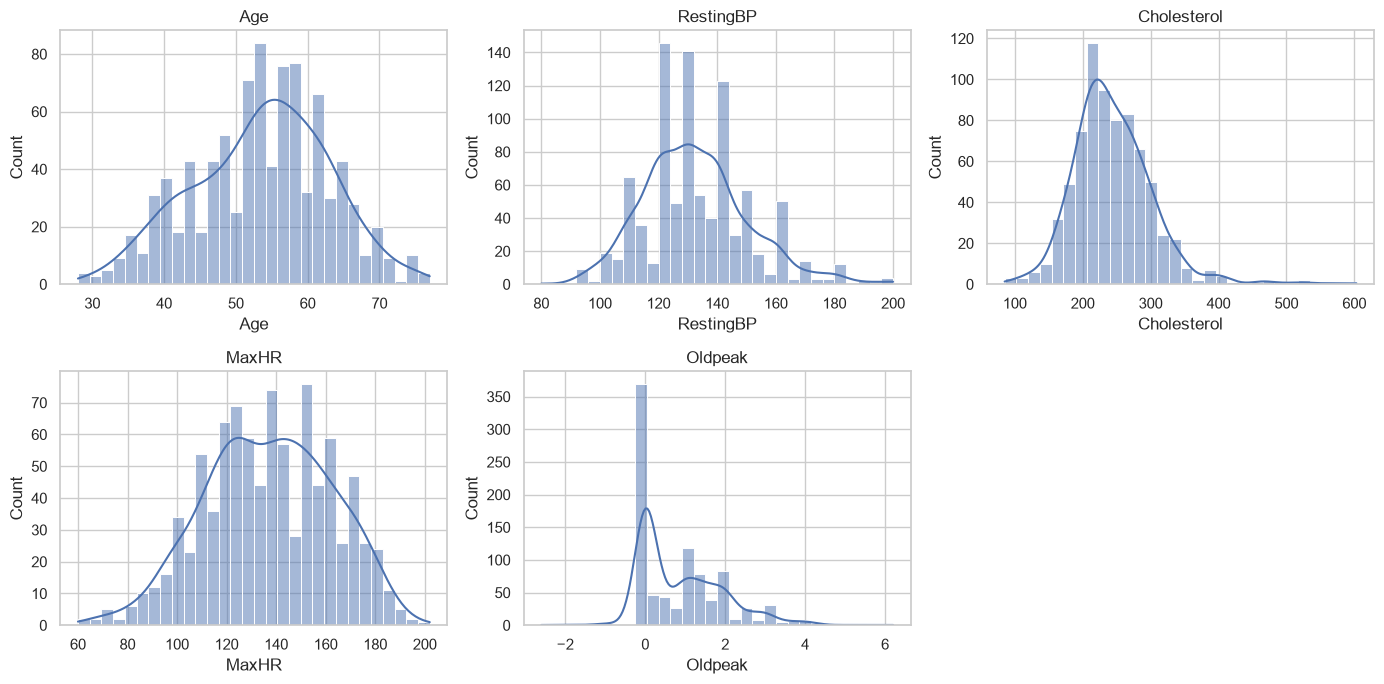

In [13]:
# Visualize the distributions of numeric columns in the cleaned dataset
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.ravel(), NUM_COLS):
    sns.histplot(df_clean[col], kde=True, bins=30, ax=ax)
    ax.set_title(col)
axes.ravel()[-1].set_visible(False)
plt.tight_layout()
save_fig("02_numeric_distributions")
plt.show()

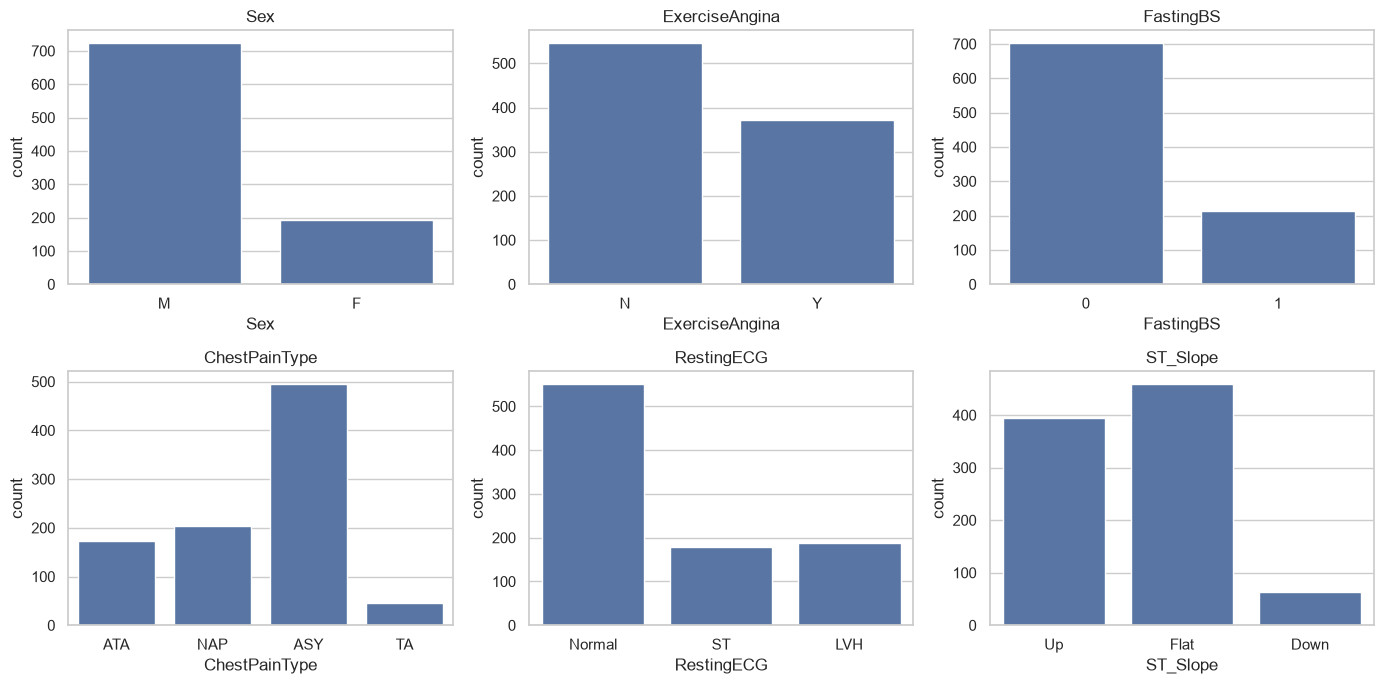

In [14]:
# Visualize the distributions of categorical columns in the cleaned dataset
cat_cols = ["Sex", "ExerciseAngina", "FastingBS", "ChestPainType", "RestingECG", "ST_Slope"]
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.ravel(), cat_cols):
    sns.countplot(data=df_clean, x=col, ax=ax)
    ax.set_title(col)
plt.tight_layout()
save_fig("03_categorical_distributions")
plt.show()

# Findings

Out of the 5 numeric features, Age and MaxHR seem to be symmetric both from the graphs and the fact that their skew is not >1 or <-1 while RestingBP appears mildly right skewed with a skew of 0.61. On the other hand, Cholesterol and Oldpeak appear right skewed as shown in the graphs and supported by their skew being >1 (1.24, 1.02). Scaling/transforming these features is needed for logistic regression algorithms, tree based models are unaffected.

Some outliers are extreme ( Cholesterol > 600, RestingBp = 200) but not physiologically impossible so it is assumed they are real measurements from real patients and will be accounted for normally.

By analysing the categorical columns it is shown that the male sex is dominant in this dataset and some rare features exist such as a Chest Pain Type of TA and ST Slope being Down.
Most patients have a FastingBS of <= 120 mg/dl, Normal RestingECg and ASY Chest Pain Type.


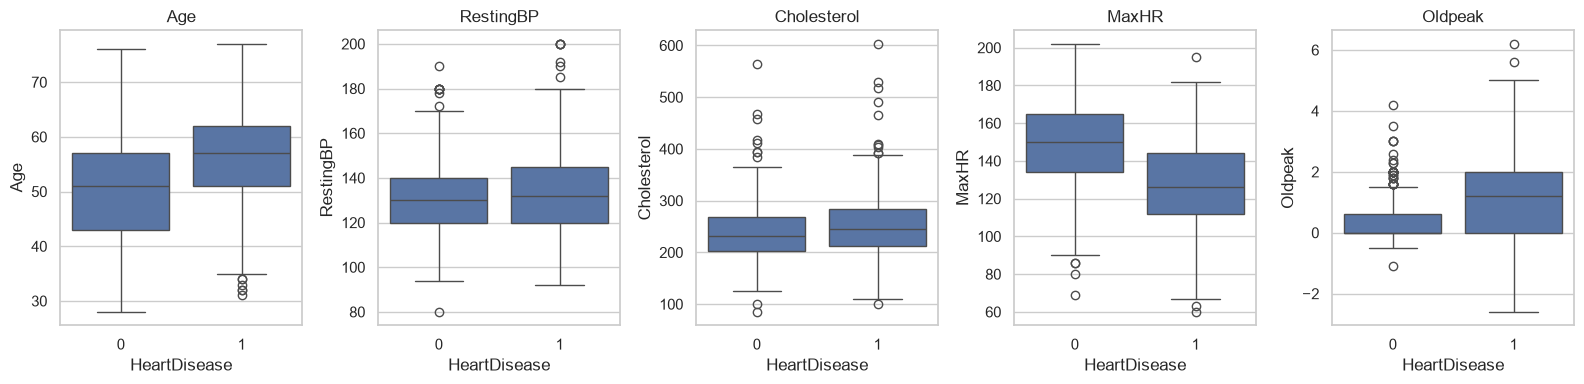

,Age,RestingBP,Cholesterol,MaxHR,Oldpeak
HeartDisease,,,,,
0,51.0,130.0,231.5,150.0,0.0
1,57.0,132.0,246.0,126.0,1.2


In [15]:
# Visualize the relationship between numeric columns and the target variable
fig, axes = plt.subplots(1, 5, figsize=(16, 4))
for ax, col in zip(axes, NUM_COLS):
    sns.boxplot(data=df_clean, x=TARGET, y=col, ax=ax)
    ax.set_title(col)
    ax.set_xlabel("HeartDisease")
plt.tight_layout()
save_fig("04_numeric_by_target")
plt.show()

df_clean.groupby(TARGET)[NUM_COLS].median().round(1)

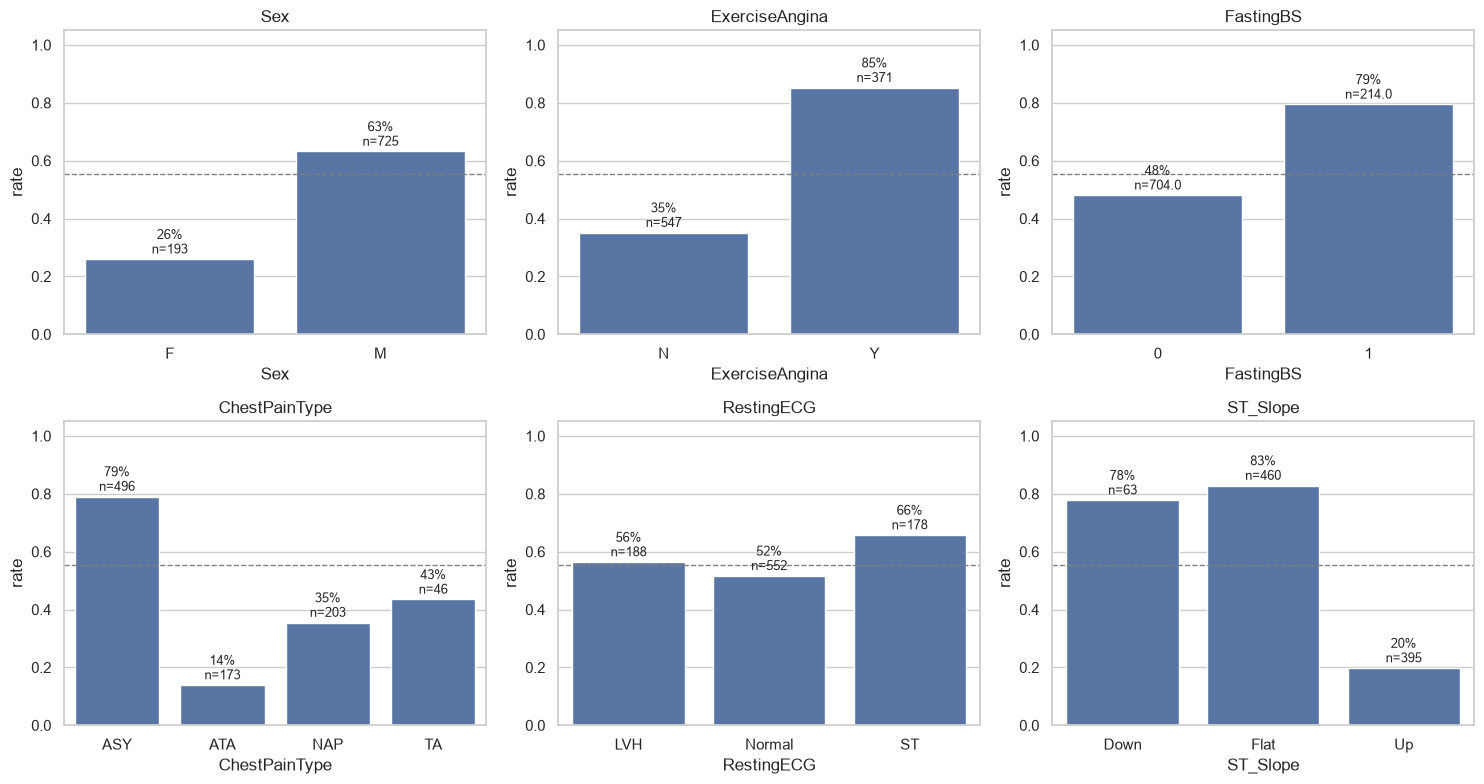

In [16]:
# Visualize the disease rate by categorical columns
base_rate = df[TARGET].mean()

def rate_plot(col: str, ax) -> None:
    g = df_clean.groupby(col)[TARGET].agg(rate="mean", n="count").reset_index()
    sns.barplot(data=g, x=col, y="rate", ax=ax)
    ax.axhline(base_rate, color="grey", ls="--", lw=1)
    ax.set_ylim(0, 1.05)
    ax.set_title(col)
    for i, row in g.iterrows():
        ax.text(i, row["rate"] + 0.02, f"{row['rate']:.0%}\nn={row['n']}", ha="center", fontsize=9)

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), cat_cols):
    rate_plot(col, ax)
plt.tight_layout()
save_fig("05_rate_by_category")
plt.show()

# Findings

From the boxplots it is observed that the disease group is generally aged 50+ which shows that the disease appears in older people while not so much in people in their 30s.
The disease group also show lower MaxHR and larger variance in Oldpeak when compared with the non diseased.

High disease rates are observed on the following features: Male (63%), Y in ExerciseAngina (85%), 1 in fastingBS (79%), ASY Chest Pain Type (79%), St RestingECG (66%), Down and Flat ST Slope (78%, 83%). Low disease rates are observed on these features: Female (26%), N in ExerciseAngina (35%), ATA in ChestPainType (14%) and Up in ST Slope (20%).

The general conclusion is that Sex, ExerciseAngina, ChestPainType and ST Slope separate the classes more that FastingBS or RestingECG.

In [17]:
# Compare the correlation of numeric features with the target variable before and after cleaning the dataset
cols = NUM_COLS + ["FastingBS", TARGET]
before = df[cols].corr()[TARGET].drop(TARGET)         
after = df_clean[cols].corr()[TARGET].drop(TARGET)    
pd.DataFrame({"raw (zeros kept)": before, "cleaned": after}).round(2)

,raw (zeros kept),cleaned
Age,0.28,0.28
RestingBP,0.11,0.12
Cholesterol,-0.23,0.10
MaxHR,-0.40,-0.40
Oldpeak,0.40,0.40
FastingBS,0.27,0.27


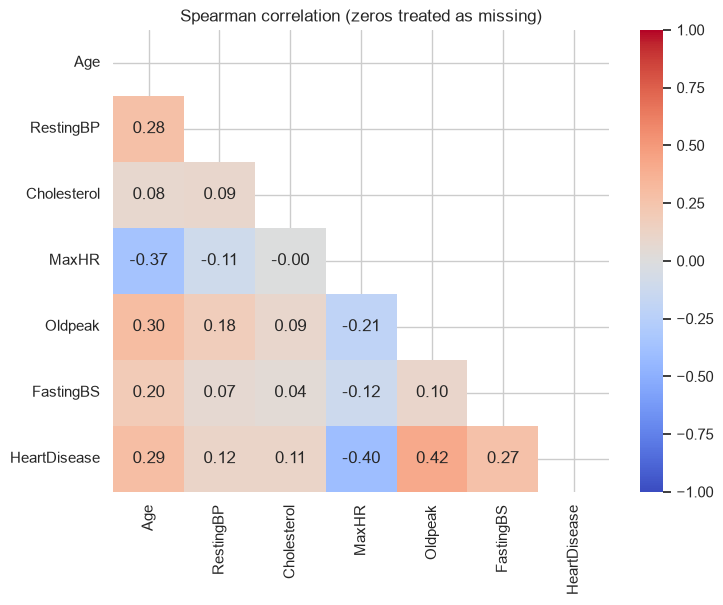

In [18]:
# Visualize the Spearman correlation matrix of the cleaned dataset
corr = df_clean[cols].corr(method="spearman")  
mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(8, 6))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Spearman correlation (zeros treated as missing)")
save_fig("06_correlation_heatmap")
plt.show()

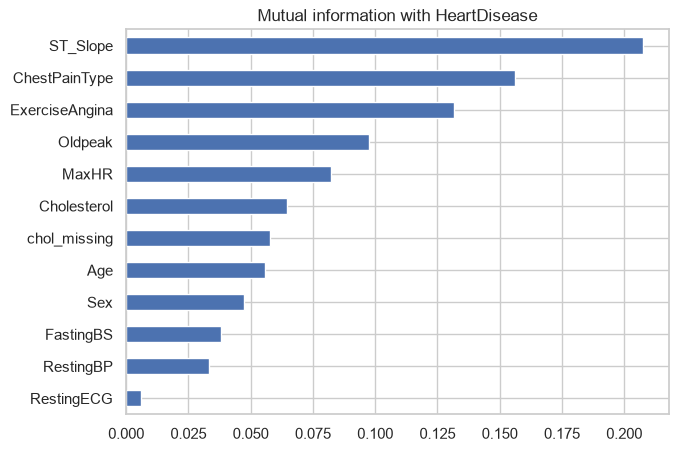

In [19]:
from sklearn.feature_selection import mutual_info_classif

# Compute mutual information between features and the target variable
X_mi = df_clean.drop(columns=TARGET).copy()
X_mi["chol_missing"] = X_mi["Cholesterol"].isna().astype(int)
num_missing = ["RestingBP", "Cholesterol"]
X_mi[num_missing] = X_mi[num_missing].fillna(X_mi[num_missing].median())
for c in BINARY_COLS + NOMINAL_COLS:
    X_mi[c] = X_mi[c].astype("category").cat.codes

discrete = X_mi.columns.isin(BINARY_COLS + NOMINAL_COLS + ["FastingBS", "chol_missing"])
mi = pd.Series(
    mutual_info_classif(X_mi, df_clean[TARGET], discrete_features=discrete, random_state=SEED),
    index=X_mi.columns,
).sort_values()

mi.plot.barh(figsize=(7, 5), title="Mutual information with HeartDisease")
save_fig("07_mutual_information")
plt.show()

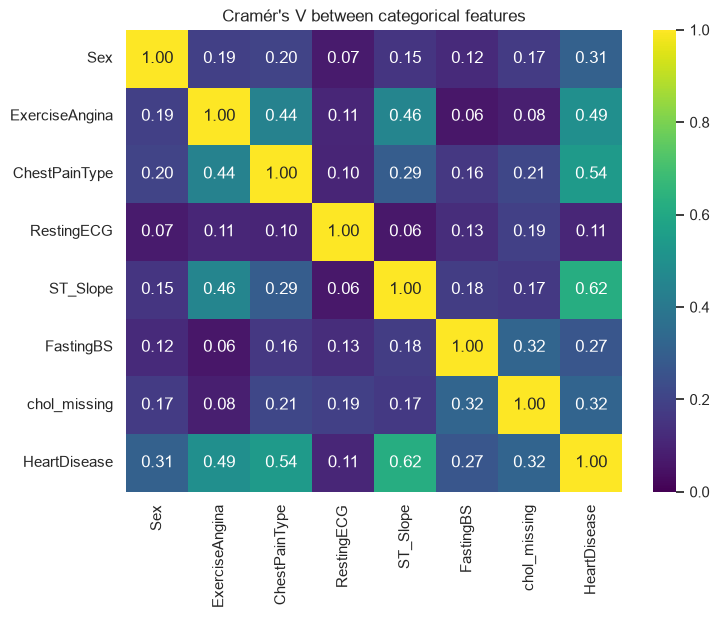

In [20]:
# Compute Cramér's V between categorical features
def cramers_v(a, b) -> float:
    ct = pd.crosstab(a, b)
    chi2 = stats.chi2_contingency(ct, correction=False)[0]
    return float(np.sqrt(chi2 / (ct.values.sum() * (min(ct.shape) - 1))))

d = df_clean.assign(chol_missing=df_clean["Cholesterol"].isna().astype(int))
cats = BINARY_COLS + NOMINAL_COLS + ["FastingBS", "chol_missing", TARGET]
V = pd.DataFrame([[cramers_v(d[a], d[b]) for b in cats] for a in cats], index=cats, columns=cats)

plt.figure(figsize=(8, 6))
sns.heatmap(V, annot=True, fmt=".2f", cmap="viridis", vmin=0, vmax=1)
plt.title("Cramér's V between categorical features")
save_fig("08_cramers_v")
plt.show()

In [21]:
# Compute Variance Inflation Factor (VIF) for numeric features to check for multicollinearity
Z = df_clean[NUM_COLS].dropna()
vif = pd.Series(np.diag(np.linalg.inv(Z.corr().values)), index=NUM_COLS, name="VIF").round(2)
vif

Age            1.28
RestingBP      1.10
Cholesterol    1.01
MaxHR          1.21
Oldpeak        1.14
Name: VIF, dtype: float64

# Findings

It is observed that the only correlation with the target variable that changes from the raw data to the clean data is Cholesterol with a +0.33 change. This is expected since it had a large number of missing/impossible values and shows that the real weak correlation was masked by these values.

3 different association techniques are implemented on the clean data: Spearman correlation, mutual information with the target variable and Cramer's V between the categorical features.
The numeric features with the highest correlation with the target variable, as per the correlation heatmap, are Olpeak (0.42) and MaxHR (-0.40). The highest mutual information with the target variable is observed on ST Slope (>0.2), ChestPainType (>0.15) and ExerciseAngina (>0.12). Lastly, Cramer's V builds on the findings of mutual information, showing strong association with the target variable on ST Slope (0.62) as well as 0.54 and 0.49 on ChestPainType and ExerciseAngina respectively.

There are not strong signs of multicolinearity as shown by VIF with the highest values being 1.28 for Age and 1.21 for MaxHR.

From these plots, it is understood that certain features are more powerful than others. A power ranking based on these findings follows:

Clear Leaders: ST Slope, ChestPainType, ExerciseAngina, Oldpeak, MaxHR.

Contradiction between diagrams/ Noise: Sex, Age, FastingBS, RestingBP, Cholesterol, chol_missing.

Least Importance: RestingECG.

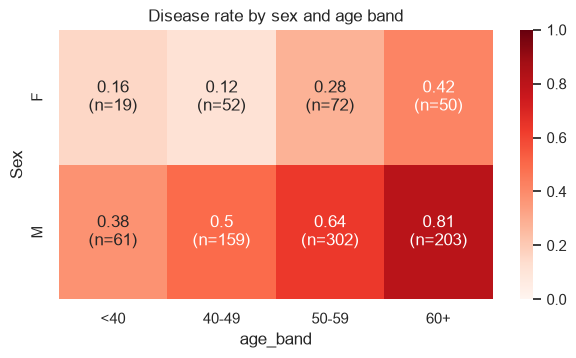

In [25]:
# Visualize the disease rate by sex and age band
d = df_clean.assign(
    age_band=pd.cut(df_clean["Age"], [0, 40, 50, 60, 100],
                    labels=["<40", "40-49", "50-59", "60+"], right=False)
)
g = d.groupby(["Sex", "age_band"], observed=True)[TARGET].agg(rate="mean", n="count")
rate, n = g["rate"].unstack(), g["n"].unstack()
annot = rate.round(2).astype(str) + "\n(n=" + n.astype(str) + ")"

plt.figure(figsize=(7, 3.5))
sns.heatmap(rate, annot=annot, fmt="", cmap="Reds", vmin=0, vmax=1)
plt.title("Disease rate by sex and age band")
save_fig("09_subgroups")
plt.show()

# Findings 

By grouping by Sex and age band (turning Age into a categorical feature) it is clear that the disease is more prevalent on older people as stated before. 0.81 rate of having the disease on males over 60 and 0.64 on 50-59 years of age. It is not as easy to make a conclusion for the women as the samples are not that many but htey seem to follow that trend as well in a lesser way. In the 60+ and 50-59 age groups form males though, there are more than enough samples to suggest that the chance of male patients having a heart disease rises significantly as they age.

In [23]:
from sklearn.metrics import roc_auc_score

# Compute univariate ROC AUC
def uni_auc(s: pd.Series) -> float:
    """Single-feature ROC AUC, direction-agnostic."""
    s = s.dropna()
    a = roc_auc_score(df_clean.loc[s.index, TARGET], s)
    return max(a, 1 - a)

ideas = pd.Series({
    "Age": uni_auc(df_clean["Age"]),
    "MaxHR": uni_auc(df_clean["MaxHR"]),
    "MaxHR / (220 - Age)": uni_auc(df_clean["MaxHR"] / (220 - df_clean["Age"])),
    "Oldpeak": uni_auc(df_clean["Oldpeak"]),
    "Oldpeak > 0": uni_auc((df_clean["Oldpeak"] > 0).astype(int)),
})
ideas.round(3).to_frame("univariate AUC")

,univariate AUC
Age,0.668
MaxHR,0.735
MaxHR / (220 - Age),0.701
Oldpeak,0.735
Oldpeak > 0,0.672


# Findings

In the above cell, some feature ideas are proposed and lightly tested. An age-adjusted MaxHR and an only postive Oldpeak. Comparing their univariate ROC AUC with the original features does not provide a useful score which means that these ideas will not help the modeling process be any better.

The only extra feature is the chol_missing flag since its statistical importance was shown in a previous step.

# Conclusions

## Desicion Log
| # | Finding | Decision | Implemented in |
|---|---|---|---|
| 1 | No missing values, duplicates, dataset roughy balanced | No action needed, accuracy is valid metric along recall | - |
| 2 | Cholesterol is 0 in 172 rows with disease rate of 88% vs 48% on recorded cholesterol | Treat as missing, impute median with indicator, then ablate | preprocessing.py, 02 |
| 3 | RestingBP is 0 in 1 row | Treat as missing, impute median | preprocessing.py |
| 4 | Oldpeak is < 0 in 13 rows | Keep as default | - | 
| 5 | Cholesterol zeros clustered between rows 293-536 | Apply stratified shuffle split | data.py, 02 |
| 6 | Cholesterol and Oldpeak are right skewed | Scale/transform if applying logistic regression | preprocessing.py, 02 |
| 7 | Outliers are extreme but not impossible | Leave default | - |
| 8 | There are specific strong categorical separators | Compare feature subsets | 02 |
| 9 | chol_missing flag may be more important than Cholesterol | Test dropping the column and keeping the flag | 02 |
| 10 | No VIF value over 1.28 | No action needed | - |

## Limitations

The dataset has only 918 rows which may result in noisy models no matter how good the preprocessing is.
There is an imbalance on the Sex of the patients with a male dominance of over 700 samples, which makes predicting for women unreliable. This imbalance along with the informative missingness of Cholesterol may result in a model that leans on data-level patterns and not medicine.
Some feature categories have too small of a sample size to be taken into account so a distinction between valuable information and noise can be hard to make.

## Questions

Questions raised by this notebook's exploratory data analysis will be modelled and answered in the modelling notebook (02_modelling.ipynb). Testing with and without the missing indicator, testing with and without the Cholesterol column, scaling effects on logistic regression will all be tested there.